In [3]:
# Pandas is a Python library mainly used for data manipulation and analysis.
import pandas as pd
# It is used for numerical calculations and array operations.
import numpy as np

# SciPy is a scientific-computing library built on top of NumPy.
import scipy.stats as stats

# Matplotlib is a Python library for creating graphs and visualizations.
import matplotlib.pyplot as plt
# Seaborn is a statistical visualization library built on top of Matplotlib.
import seaborn as sns

# train_test_split() divides your dataset into training data and testing data.
from sklearn.model_selection import train_test_split
# accuracy_score() measures how many predictions your classification model got correct.
from sklearn.metrics import accuracy_score
# Instead of evaluating your model using only one train/test split, it divides the training data into multiple parts.
from sklearn.model_selection import cross_val_score

# Instead of evaluating your model using only one train/test split, it divides the training data into multiple parts.
from sklearn.linear_model import LogisticRegression
# A Decision Tree is a classification algorithm that makes decisions using a tree-like structure.
from sklearn.tree import DecisionTreeClassifier

# FunctionTransformer allows you to apply a custom Python function to your features while keeping the transformation compatible with Scikit-learn. 
from sklearn.preprocessing import FunctionTransformer
# ColumnTransformer allows you to apply different transformations to different columns.
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor

In [6]:
titanic = pd.read_csv("train.csv", usecols= ["Age", "Fare", "Survived"])
titanic.columns

Index(['Survived', 'Age', 'Fare'], dtype='object')

In [7]:
titanic.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [8]:
titanic.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [9]:
titanic["Age"] = titanic["Age"].fillna(titanic["Age"].mean())

In [10]:
titanic.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [11]:
titanic[titanic["Age"] == titanic["Age"].mean()]

,Survived,Age,Fare
5,0,29.699118,8.4583
17,1,29.699118,13.0000
19,1,29.699118,7.2250
26,0,29.699118,7.2250
28,1,29.699118,7.8792
...,...,...,...
859,0,29.699118,7.2292
863,0,29.699118,69.5500
868,0,29.699118,9.5000
878,0,29.699118,7.8958


In [12]:
x = titanic.iloc[:, 1:3]
y = titanic.iloc[:, 0]

X_train, X_test, Y_train, Y_test = train_test_split(
    x,
    y, 
    test_size= 0.2, 
    random_state= 42
)

C:\Users\Asus\AppData\Local\Temp\ipykernel_1768\3819304795.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train["Age"])


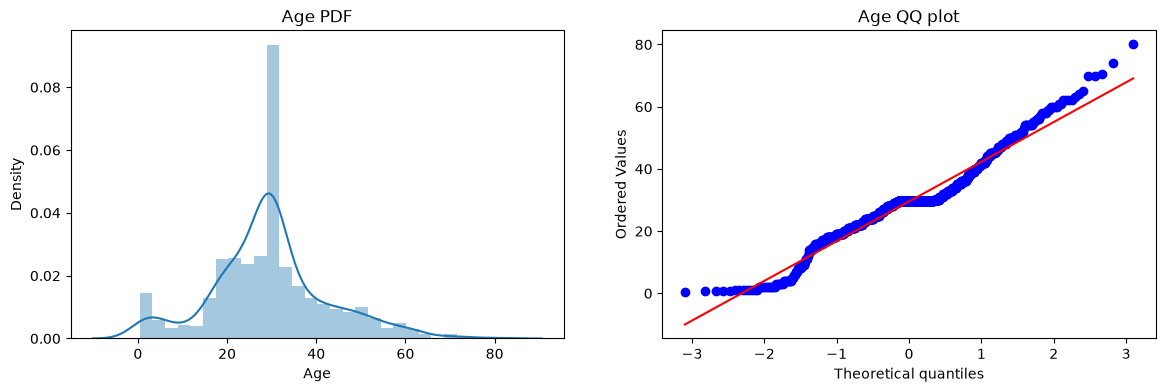

In [13]:
plt.figure(figsize= (14, 4))

# plt.subplot(121) vs plt.subplot(1, 2, 1), both are same
plt.subplot(1,2,1)
sns.distplot(X_train["Age"])
plt.title("Age PDF")

plt.subplot(1,2,2)
# creates a Q-Q plot. Quantile-Quantile
# It is commonly used to determine whether your data approximately follows a particular theoretical distribution.
# dist="norm", This tells SciPy what theoretical distribution you want to compare your data against.
# plot=plt, Use Matplotlib's plt to draw the Q-Q plot.
stats.probplot(X_train["Age"], dist= "norm", plot= plt)
plt.title("Age QQ plot")

plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_1768\4190128266.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train["Fare"])


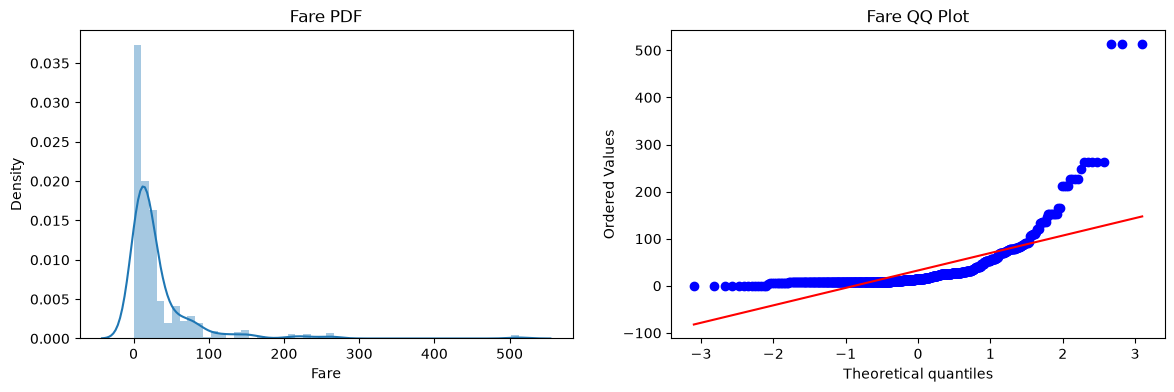

In [14]:
plt.figure(figsize= (14, 4))

plt.subplot(1, 2, 1) 
sns.distplot(X_train["Fare"])
plt.title("Fare PDF")

plt.subplot(1, 2, 2)
stats.probplot(X_train["Fare"], dist= "norm", plot= plt) 
plt.title("Fare QQ Plot")

plt.show()

In [15]:
# In QQ plot, the more the data is on the line the more it follows normal distribution

In [16]:
# Firstly we are creating 2 objects: 1 for Logistic Regression and other one for Decision Tree Classifier

# Logistic Regression ka model create kar rahe hain
# Ye classification problems ke liye use hota hai
reg = LogisticRegression()

# Decision Tree Classifier ka model create kar rahe hain
# Ye bhi classification problems ke liye use hota hai
clf = DecisionTreeClassifier()

In [17]:
# Logistic Regression ko training data par train/fit kar rahe hain
reg.fit(X_train, Y_train)

# Decision Tree Classifier ko same training data par train kar rahe hain
# Isse hum dono models ko same data par compare kar sakte hain
clf.fit(X_train, Y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [18]:
# Predicting Y_test using both Algorithms

y_pred = reg.predict(X_test)
y_pred1 = clf.predict(X_test)

# Checking the Accuracy Score of both Algo's 

print("Accuracy Score by LogisticRegression: ", accuracy_score(y_pred, Y_test))
print("Accuracy Score by DecisionTreeClassifier: ", accuracy_score(y_pred1, Y_test))

Accuracy Score by LogisticRegression:  0.6480446927374302
Accuracy Score by DecisionTreeClassifier:  0.6927374301675978


## Log Transformation

In [21]:
# By plotting the graph of AGE and FARE we found out that the Data is RIGHT SKEWED, So now we will be using Log Transformation 

# Creating LogTransformer object and transforming data as per it 

LT = FunctionTransformer(np.log1p)

X_train_transformed = LT.fit_transform(X_train)
X_test_transformed = LT.transform(X_test)

# Now fit in LogisticRegression and DecisionTreeClassifier then Prediction

reg2 = LogisticRegression()
clf2 = DecisionTreeClassifier() 

reg2.fit(X_train_transformed, Y_train)
clf2.fit(X_train_transformed, Y_train)

y_pred2 = reg2.predict(X_test)
y_pred3 = clf2.predict(X_test)

In [23]:
# Now I'm checcking accuracy scores without LOg Transformer and With LogTransformer for both the Algorithms

print("Accuracy of LR without LogTransformer: ", accuracy_score(y_pred, Y_test)*100)
print("Accuracy of DTC without LogTransformer: ", accuracy_score(y_pred1, Y_test)*100)


print("Accuracy of LR with LogTransformer: ", accuracy_score(y_pred2, Y_test)*100)
print("Accuracy of DTC with LogTransformer: ", accuracy_score(y_pred3, Y_test)*100)


Accuracy of LR without LogTransformer:  64.80446927374301
Accuracy of DTC without LogTransformer:  69.27374301675978
Accuracy of LR with LogTransformer:  73.74301675977654
Accuracy of DTC with LogTransformer:  58.659217877094974


Text(0.5, 1.0, 'Fare without Log')

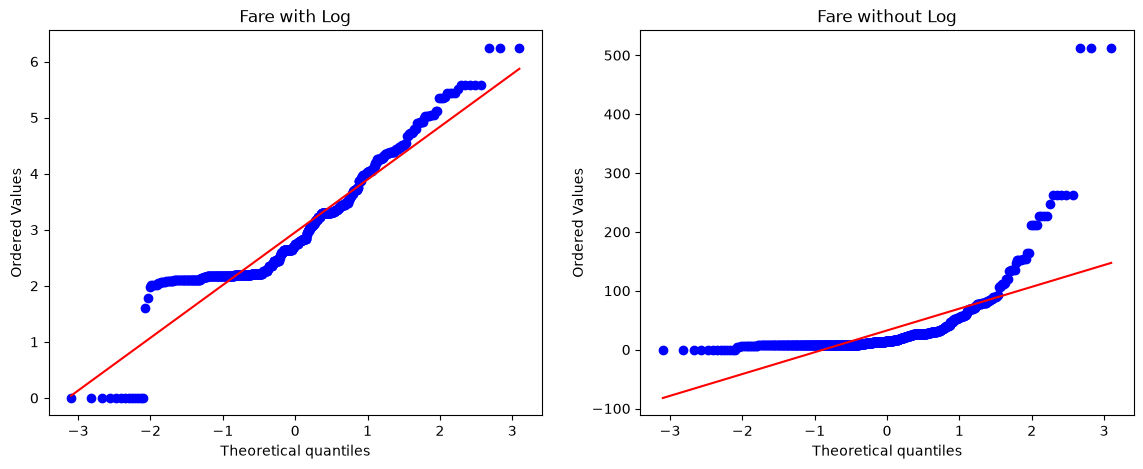

In [25]:
# Now we will plot the QQ Plot to check any difference on age and Fare

plt.figure(figsize=(14, 5))

plt.subplot(1,2,1)
stats.probplot(X_train_transformed["Fare"], dist= "norm", plot= plt)
plt.title("Fare with Log")


plt.subplot(1,2,2)
stats.probplot(X_train["Fare"], dist= "norm", plot= plt)
plt.title("Fare without Log")

Text(0.5, 1.0, 'Age without Log')

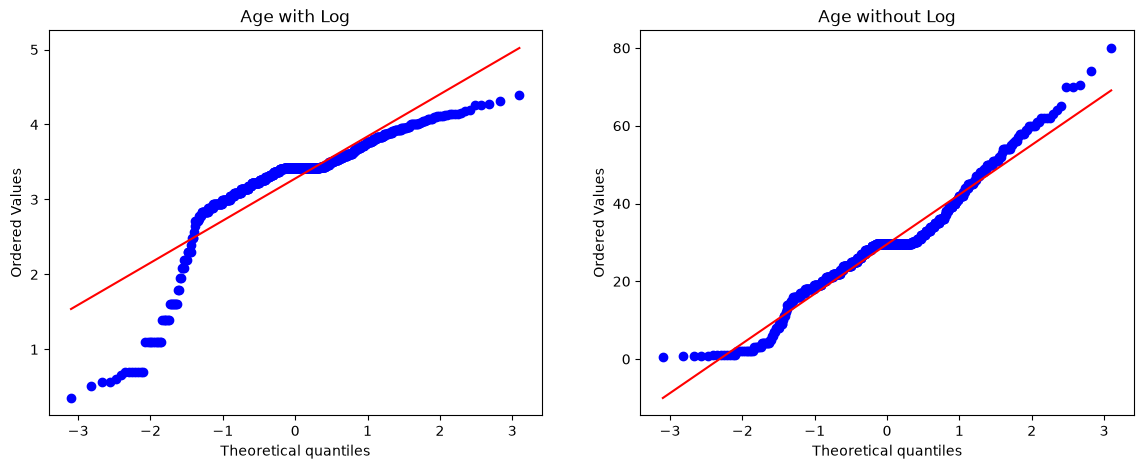

In [26]:
plt.figure(figsize=(14, 5))

plt.subplot(1,2,1)
stats.probplot(X_train_transformed["Age"], dist= "norm", plot= plt)
plt.title("Age with Log")


plt.subplot(1,2,2)
stats.probplot(X_train["Age"], dist= "norm", plot= plt)
plt.title("Age without Log")

In [31]:
# Here we saw that the Fare is working good with Log but it's opposite for Age, So we will apply Log on Fare and let the Age be as it is

trnfs = ColumnTransformer(
    [
        ("Log", FunctionTransformer(np.log1p), ["Fare"])
    ], 
    remainder= "passthrough"
)


X_train_transformed_2 = trnfs.fit_transform(X_train)
X_test_transformed_2 = trnfs.transform(X_test)

In [32]:
reg3 = LogisticRegression()
clf3 = DecisionTreeClassifier()

reg3.fit(X_train_transformed_2, Y_train)
clf3.fit(X_train_transformed_2, Y_train)


y_pred4 = reg3.predict(X_test_transformed_2)
y_pred5 = clf3.predict(X_test_transformed_2)

In [33]:
print("New Axxuracies:")
print("Accuracy of LR: ", accuracy_score(y_pred4, Y_test))
print("Accuracy of DTC: ", accuracy_score(y_pred5, Y_test))

New Axxuracies:
Accuracy of LR:  0.6703910614525139
Accuracy of DTC:  0.6703910614525139


## Log Transform in Pipeline

In [47]:
cars = pd.read_csv("cars.csv", usecols=['brand', 'km_driven', 'fuel', 'selling_price'])
cars

,brand,km_driven,fuel,selling_price
0,Maruti,145500,Diesel,450000
1,Skoda,120000,Diesel,370000
2,Honda,140000,Petrol,158000
3,Hyundai,127000,Diesel,225000
4,Maruti,120000,Petrol,130000
...,...,...,...,...
8123,Hyundai,110000,Petrol,320000
8124,Hyundai,119000,Diesel,135000
8125,Maruti,120000,Diesel,382000
8126,Tata,25000,Diesel,290000


In [48]:
cars.columns

Index(['brand', 'km_driven', 'fuel', 'selling_price'], dtype='object')

In [50]:
# First we are checking null values only then we will apply Simple Imputer

cars.isnull().sum()

brand            0
km_driven        0
fuel             0
selling_price    0
dtype: int64

In [59]:
# Train_test_split

X1_train, X1_test, Y1_train, Y1_test = train_test_split(
    cars.drop(columns= ['selling_price']),
    cars['selling_price'],
    test_size= .2,
    random_state= 42
)

In [71]:
# Now we will apply One Hot Encoding

# transformer1 = ColumnTransformer(
#     transformers= [
#         ("oneHotbrand&fuel", OneHotEncoder(sparse_output=False, handle_unknown= "ignore"), [0, 2])
#     ],
#     remainder= "passthrough"
# )

In [72]:
# Creating an object of log transformer for Km driven and selling price

logTransformer = FunctionTransformer(np.log1p)

# Now using columnTransformer

transformer2 = ColumnTransformer(
    transformers= [
        ("KM", logTransformer, [1]),
        ("oneHotbrand&fuel", OneHotEncoder(sparse_output=False, handle_unknown= "ignore"), [0, 2])
    ],
    remainder="passthrough"
)

In [79]:
transformer3 = DecisionTreeRegressor(random_state=42)

In [80]:
# Now we will create Pipeline

pipe = make_pipeline(transformer2, transformer3)

In [81]:
# Now training the model

pipe.fit(X1_train, Y1_train)

,steps,"[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('KM', ...), ('oneHotbrand&fuel', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [82]:
# prediction

Y1_predict = pipe.predict(X1_test)

In [87]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

print("R2 Score:", r2_score(Y1_test, Y1_predict))
print("Score: ", pipe.score(X1_test, Y1_predict))
print("MAE:", mean_absolute_error(Y1_test, Y1_predict))
print("RMSE:", root_mean_squared_error(Y1_test, Y1_predict))

R2 Score: 0.7992766341970287
Score:  1.0
MAE: 184427.80296059346
RMSE: 362727.2296223466
